# EnergyGreen — Previsão de consumo de energia com LSTM e GRU

**CASE 3 — Previsão de Consumo de Energia.** Este notebook documenta o experimento de ponta a ponta:
origem e organização dos dados, estruturação da série temporal, arquitetura, treinamento, métricas e
interpretação dos resultados.

Toda a lógica vive em `src/` (o mesmo código usado pela API); aqui ela é apenas chamada e inspecionada.
Os modelos são treinados por `python -m src.train`; este notebook **carrega** os pesos e o histórico
de treino salvos em `models/` (mude `RETREINAR = True` para treinar de novo aqui — leva alguns minutos em CPU).

In [1]:
import os, sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

from src import data, models, train, evaluate
from src.data import ALVO
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
RETREINAR = False
print("torch", torch.__version__, "| pandas", pd.__version__, "| threads", torch.get_num_threads())

torch 2.15.0+cpu | pandas 3.1.1 | threads 2


## 1. Dados: origem e organização

**Individual Household Electric Power Consumption** — UCI Machine Learning Repository (id 235).
Medições a cada minuto de uma residência em Sceaux (França), de dezembro de 2006 a novembro de 2010.
O arquivo é baixado por `src.data.baixar_dataset()` diretamente do UCI.

| Coluna | Significado |
|---|---|
| `Global_active_power` | potência ativa média no minuto (kW) — **alvo** |
| `Global_reactive_power` | potência reativa (kW) |
| `Voltage` | tensão (V) |
| `Global_intensity` | corrente (A) |
| `Sub_metering_1..3` | energia (Wh) da cozinha; lavanderia; aquecedor de água + ar-condicionado |

In [2]:
horario = data.carregar_horario()
a = horario.attrs
print(f"Linhas por minuto: {a['linhas_brutas']:,}")
print(f"Período bruto: {a['inicio_bruto']} -> {a['fim_bruto']}")
print(f"Minutos sem medição ('?'): {a['faltantes_brutos']:,} ({a['pct_faltantes_brutos']:.2f}%)")
print(f"Série horária: {len(horario):,} horas; horas sem nenhum dado antes do preenchimento: {a['faltantes_preenchidos']}")
horario.head()

Linhas por minuto: 2,075,259
Período bruto: 2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Minutos sem medição ('?'): 25,979 (1.25%)
Série horária: 34,589 horas; horas sem nenhum dado antes do preenchimento: 421


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667


In [3]:
horario.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Global_active_power,34589.0,1.089,0.896,0.124,0.341,0.800,1.578,6.561
Global_reactive_power,34589.0,0.124,0.067,0.000,0.078,0.107,0.150,0.774
Voltage,34589.0,240.846,2.996,225.834,239.200,240.985,242.693,251.902
Global_intensity,34589.0,4.618,3.753,0.503,1.510,3.407,6.593,28.383
Sub_metering_1,34589.0,1.121,3.538,0.000,0.000,0.000,0.000,48.367
Sub_metering_2,34589.0,1.296,4.185,0.000,0.000,0.333,0.650,46.433
Sub_metering_3,34589.0,6.453,7.345,0.000,0.650,1.650,14.167,21.550


### Análise exploratória

Consumo médio diário ao longo dos quatro anos, perfil médio por hora do dia e por dia da semana, e a
autocorrelação nas defasagens de 1 h, 24 h e 168 h (que justifica o baseline sazonal e a janela de 7 dias).

In [4]:
fig, ax = plt.subplots()
horario[ALVO].resample("D").mean().plot(ax=ax, lw=.8, color="#2a78d6")
horario[ALVO].resample("30D").mean().plot(ax=ax, lw=2, color="#0b0b0b", label="média de 30 dias")
ax.set_ylabel("kW"); ax.set_title("Consumo ativo — média diária"); ax.legend(["média diária", "média de 30 dias"]);

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
perfil = horario.groupby([horario.index.hour, horario.index.day_of_week >= 5])[ALVO].mean().unstack()
perfil.columns = ["dia útil", "fim de semana"]
perfil.plot(ax=a1, marker="o", ms=3); a1.set_xlabel("hora do dia"); a1.set_ylabel("kW"); a1.set_title("Perfil médio diário")
mensal = horario[ALVO].groupby(horario.index.month).mean()
mensal.plot.bar(ax=a2, color="#2a78d6"); a2.set_xlabel("mês"); a2.set_title("Sazonalidade anual (média por mês)")
plt.tight_layout()

In [6]:
for lag in (1, 24, 168):
    print(f"autocorrelação lag {lag:>3} h: {horario[ALVO].autocorr(lag):.3f}")
print(f"\nAssimetria: {horario[ALVO].skew():.2f} | p99 = {horario[ALVO].quantile(.99):.2f} kW | mínimo = {horario[ALVO].min():.3f} kW")

autocorrelação lag   1 h: 0.713
autocorrelação lag  24 h: 0.436
autocorrelação lag 168 h: 0.466

Assimetria: 1.30 | p99 = 3.92 kW | mínimo = 0.124 kW


## 2. Estruturação da série temporal

1. **Limpeza** — `Date`+`Time` viram índice datetime; `?` vira NaN; colunas numéricas.
2. **Reamostragem** — média horária (reduz ruído e viabiliza CPU).
3. **Faltantes** — lacunas de até 6 h interpoladas no tempo; lacunas longas recebem o valor da mesma hora da semana anterior.
4. **Features** — 7 medições + seno/cosseno da hora + seno/cosseno do dia da semana + flag de fim de semana (12 no total).
5. **Divisão cronológica** 70/15/15, sem embaralhar.
6. **Normalização** — `StandardScaler` ajustado **somente no treino**.
7. **Janelas** — X = 168 h × 12 features → y = 24 h seguintes de `Global_active_power`, dentro de cada divisão (nenhuma janela cruza fronteiras).

In [7]:
cfg = models.Config()
dados = data.preparar_tudo(passo_treino=cfg.passo_treino)
for nome in ("treino", "validacao", "teste"):
    p = dados[f"df_{nome}"]
    print(f"{nome:<10} {p.index.min()} -> {p.index.max()} ({len(p):>6,} h)  X={dados[f'X_{nome}'].shape}  y={dados[f'y_{nome}'].shape}")
print("features:", data.FEATURES)
print(f"passo entre janelas de treino: {cfg.passo_treino} (validação e teste: 1)")

treino     2006-12-16 17:00:00 -> 2009-09-20 12:00:00 (24,212 h)  X=(4805, 168, 12)  y=(4805, 24)
validacao  2009-09-20 13:00:00 -> 2010-04-24 16:00:00 ( 5,188 h)  X=(4997, 168, 12)  y=(4997, 24)
teste      2010-04-24 17:00:00 -> 2010-11-26 21:00:00 ( 5,189 h)  X=(4998, 168, 12)  y=(4998, 24)
features: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'hora_sin', 'hora_cos', 'dia_sin', 'dia_cos', 'fim_de_semana']
passo entre janelas de treino: 5 (validação e teste: 1)


In [8]:
# Verificações de vazamento
tr, va, te = dados["df_treino"], dados["df_validacao"], dados["df_teste"]
assert tr.index.max() < va.index.min() and va.index.max() < te.index.min()
assert np.isclose(dados["scaler"].mean_[0], tr[ALVO].mean())          # scaler só do treino
primeira_entrada_teste = dados["inicio_teste"][0] - pd.Timedelta(hours=168)
assert primeira_entrada_teste >= te.index[0]                           # janelas de teste só usam dados de teste
print("OK: divisão cronológica, scaler ajustado só no treino, janelas de teste dentro do teste.")
print(f"média do alvo — treino {tr[ALVO].mean():.3f} kW | validação {va[ALVO].mean():.3f} | teste {te[ALVO].mean():.3f}")

OK: divisão cronológica, scaler ajustado só no treino, janelas de teste dentro do teste.
média do alvo — treino 1.086 kW | validação 1.249 | teste 0.943


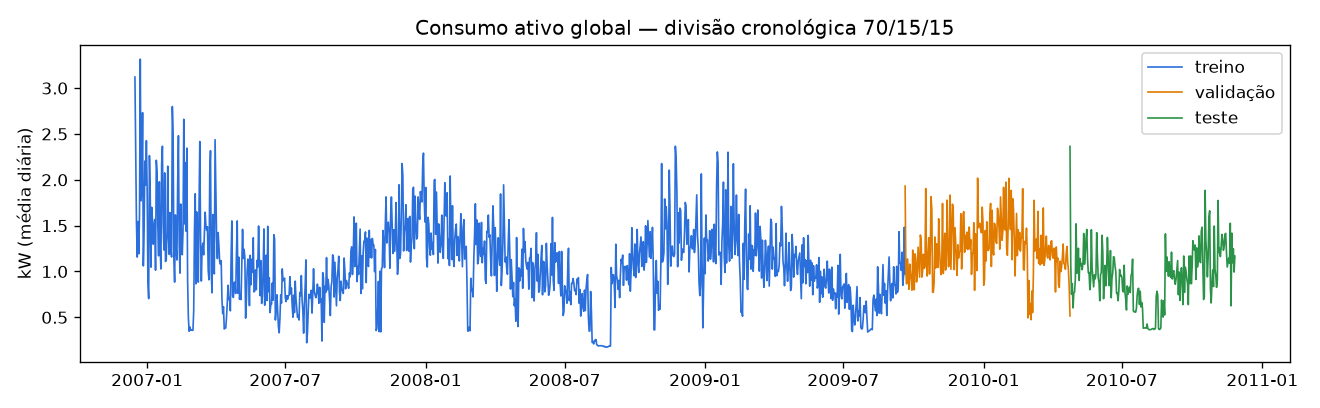

In [9]:
display(Image("reports/figures/divisao_serie.png"))

## 3. Arquitetura

- **Baseline sazonal ingênuo:** as próximas 24 h repetem as últimas 24 h observadas.
- **LSTM / GRU:** 2 camadas recorrentes de 64 unidades, dropout 0,2 entre camadas; o último estado oculto
  passa por `Linear(64, 24)` e gera as 24 horas de uma vez (previsão multi-passo direta, sem realimentação de erros).

In [10]:
for nome in ("lstm", "gru"):
    m = models.criar_modelo(nome, len(data.FEATURES))
    print(m, f"\nparâmetros treináveis: {sum(p.numel() for p in m.parameters()):,}\n")
print("Config:", cfg.dict())

LSTMForecaster(
  (rnn): LSTM(12, 64, num_layers=2, batch_first=True, dropout=0.2)
  (saida): Linear(in_features=64, out_features=24, bias=True)
) 
parâmetros treináveis: 54,808

GRUForecaster(
  (rnn): GRU(12, 64, num_layers=2, batch_first=True, dropout=0.2)
  (saida): Linear(in_features=64, out_features=24, bias=True)
) 
parâmetros treináveis: 41,496

Config: {'entrada': 168, 'horizonte': 24, 'hidden': 64, 'camadas': 2, 'dropout': 0.2, 'lr': 0.001, 'batch': 64, 'epocas': 30, 'paciencia': 5, 'plateau_fator': 0.5, 'plateau_paciencia': 2, 'passo_treino': 5, 'semente': 42}


## 4. Treinamento

Adam (lr 1e-3), perda MSE na escala normalizada, lote 64, até 30 épocas, *early stopping* com paciência 5
restaurando os melhores pesos, `ReduceLROnPlateau` (fator 0,5, paciência 2), semente 42.

In [11]:
if RETREINAR:
    train.main([])
metricas = json.loads(Path("models/metrics.json").read_text(encoding="utf-8"))
resumo = pd.DataFrame({m: {"épocas executadas": h["epocas_executadas"], "melhor época": h["melhor_epoca"],
                           "melhor perda val.": round(h["melhor_perda_validacao"], 4),
                           "early stopping": h["early_stopping"], "tempo (s)": round(h["tempo_treino_s"])}
                       for m, h in metricas["treino"].items()}).T
resumo

,épocas executadas,melhor época,melhor perda val.,early stopping,tempo (s)
lstm,11,6,0.5597,True,121
gru,15,10,0.5354,True,466


In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (m, h) in zip(eixos, metricas["treino"].items()):
    ep = range(1, len(h["perda_treino"]) + 1)
    ax.plot(ep, h["perda_treino"], label="treino"); ax.plot(ep, h["perda_validacao"], "--", label="validação")
    ax.axvline(h["melhor_epoca"], color="gray", ls=":", label="melhor época")
    ax.set_title(m.upper()); ax.set_xlabel("época"); ax.set_ylabel("MSE"); ax.legend()
plt.tight_layout()

## 5. Avaliação no conjunto de teste

Métricas em kW (escala original, após desnormalizar), sobre **todas** as janelas de teste (passo 1):
MAE, RMSE, WAPE (Σ|erro| / Σ|real|) e R². O MAPE foi deixado de fora de propósito: com consumo perto de
zero nas madrugadas ele explode e passa a medir mais o denominador do que o modelo.

In [13]:
prev = evaluate.previsoes_teste(dados)
tabela = pd.DataFrame({evaluate.NOMES[m]: evaluate.calcular_metricas(prev["real"], prev[m])
                       for m in ("lstm", "gru", "baseline")}).T
tabela.columns = ["MAE (kW)", "RMSE (kW)", "WAPE", "R²"]
tabela.round(4)

,MAE (kW),RMSE (kW),WAPE,R²
LSTM,0.4260,0.5916,0.4511,0.3053
GRU,0.4339,0.5940,0.4595,0.2997
Baseline sazonal,0.4969,0.7441,0.5261,-0.0990


In [14]:
# Os números acima são recalculados aqui e devem coincidir com models/metrics.json (gerado por src.evaluate)
for m in ("lstm", "gru", "baseline"):
    assert np.isclose(metricas["teste"][m]["mae"], tabela.loc[evaluate.NOMES[m], "MAE (kW)"], atol=1e-6)
base = tabela.loc["Baseline sazonal", "MAE (kW)"]
for m in ("LSTM", "GRU"):
    print(f"{m}: MAE {100 * (base - tabela.loc[m, 'MAE (kW)']) / base:+.1f}% vs baseline | "
          f"RMSE {100 * (tabela.loc['Baseline sazonal', 'RMSE (kW)'] - tabela.loc[m, 'RMSE (kW)']) / tabela.loc['Baseline sazonal', 'RMSE (kW)']:+.1f}%")

LSTM: MAE +14.3% vs baseline | RMSE +20.5%
GRU: MAE +12.7% vs baseline | RMSE +20.2%


In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
for m in ("lstm", "gru", "baseline"):
    a1.plot(range(1, 25), evaluate.erro_por_horizonte(prev["real"], prev[m]), marker="o", ms=3, label=evaluate.NOMES[m], color=evaluate.CORES[m])
    a2.plot(range(24), evaluate.erro_por_hora_do_dia(prev["real"], prev[m], prev["inicios"]), marker="o", ms=3, label=evaluate.NOMES[m], color=evaluate.CORES[m])
a1.set_title("MAE por horizonte"); a1.set_xlabel("horas à frente"); a1.set_ylabel("kW"); a1.legend()
a2.set_title("MAE por hora do dia prevista"); a2.set_xlabel("hora"); a2.legend()
plt.tight_layout()

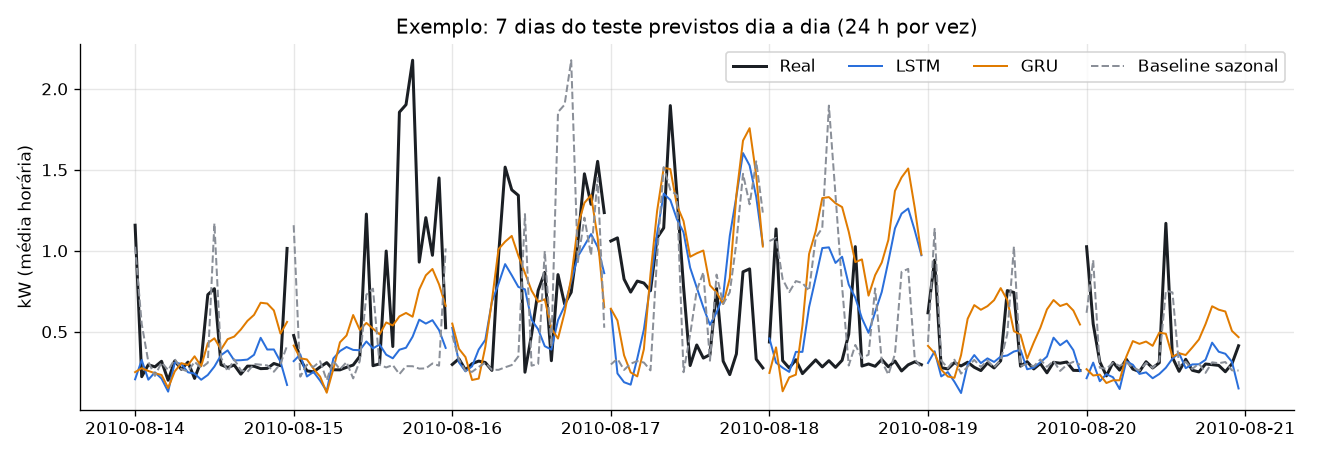

In [16]:
display(Image("reports/figures/exemplo_previsao.png"))

### Onde o modelo erra: picos

Comparamos o erro nas horas em que o consumo real ficou acima do percentil 90 com o erro no restante.

In [17]:
real = prev["real"]; p90 = np.quantile(real, .9)
alto = real > p90
linhas = {}
for m in ("lstm", "gru", "baseline"):
    e = np.abs(prev[m] - real)
    linhas[evaluate.NOMES[m]] = {"MAE horas de pico (>p90)": e[alto].mean(), "MAE demais horas": e[~alto].mean(),
                                 "viés nos picos (prev - real)": (prev[m] - real)[alto].mean()}
print(f"p90 do consumo real no teste: {p90:.2f} kW")
pd.DataFrame(linhas).T.round(3)

p90 do consumo real no teste: 1.92 kW


,MAE horas de pico (>p90),MAE demais horas,viés nos picos (prev - real)
LSTM,1.026,0.359,-1.007
GRU,0.935,0.378,-0.898
Baseline sazonal,1.065,0.434,-0.897


## 6. Interpretação crítica

A interpretação completa (com os números acima) está no `README.md`, seção *Análise crítica*. Em resumo:

- As redes são comparadas a um baseline sazonal honesto; o ganho é medido em MAE, RMSE e WAPE sobre o mesmo conjunto de teste.
- As redes tendem a **suavizar** a curva: acertam o nível e o formato médio do dia, mas subestimam picos curtos (viés negativo nas horas > p90), que dependem de eventos não observáveis (alguém liga o forno ou o aquecedor).
- O erro cresce pouco com o horizonte nas redes — a previsão multi-passo direta evita acumular erro.
- Limitações: uma única residência; nenhuma variável de clima ou feriado; dados de 2006–2010; conjunto de teste de abril a novembro (estações mais quentes que boa parte do treino).